# Does prior correction at λ = 1 survive on the small-label datasets?

**Question.** On ImageNet-C and DomainNet, prior correction (pc) only worked at λ = 1, chosen post-hoc (`../2026-10-25_stacking/`). λ = 2 was originally tuned on CIFAR. Before λ = 1 goes to a held-out dataset, does it still help on CIFAR-10-C, CIFAR-100-C and EuroSAT, or does it give up the gains λ = 2 had there?

**Pre-registration** (`PREREGISTRATION.md`, written before any λ = 1 number was computed on these datasets). λ = 1 passes on a dataset if its mean gain over Ramen is (i) above the noise floor **and** (ii) at least 50% of the λ = 2 gain. Pass on all three → λ = 1 is the single setting for the held-out test.

**Variants** (offline transforms of saved Ramen outputs; no labels used except for scoring):

| Name | What it is |
|---|---|
| Ramen + pc(lam=λ) | logit − λ·log(π_t / uniform), π_t = EMA (m = 0.99) of the predicted class marginal, batch by batch, current batch included |
| Ramen + knn | 0.5·p + 0.5·(weighted mean of p over the 10 most similar images of earlier batches, zero-shot CLIP features, softmax(sim / 0.01)) |
| Ramen + knn + pc(lam=λ) | knn, then pc |

T3 is left out here: it does not help with ≤ 100 classes (CIFAR-100-C −0.15), so the frozen setting applies pc to Ramen on small label spaces.

**Data.** CIFAR-10-C (ViT-B/32) and CIFAR-100-C (ViT-B/16): 15 corruptions × 10,000 images, severity 5. EuroSAT (ViT-B/16): 27,000 satellite images, 10 classes, one domain. One shuffled mixed stream each, batches of 100.

**Seeds.** 0–4. A seed sets the stream order; the images are the same. NoAdapt features from seed 0 are realigned to every seed.

**How the numbers were produced.** `python lambda_check.py` (seconds per seed on one GPU). It reads the cached Ramen probabilities in `results/` and the stacking code in `../2026-10-25_stacking/stack.py`, and writes `results/lambda1_check/gains.csv`.

**What counts as a result.** The pre-registered rule above. Noise floor = 2 × (max − min) of Ramen's domain-averaged accuracy over seeds 0–4: CIFAR-10-C 0.31, CIFAR-100-C 0.21, EuroSAT 1.51.

**Sections.** 1 Setup · 2 Data · 3 Sanity check · 4 Results · 5 Decision · 6 Interpretation · 7 Glossary

## 1. Setup

In [1]:
import os, sys
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '')
sys.path.insert(0, '..'); sys.path.insert(0, '../2026-10-25_stacking')
import pandas as pd
import stack, lambda_check as lc
pd.set_option('display.width', 200)
t = lc.load()
t.groupby('dataset').seed.unique()

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


dataset
CIFAR100C    [0, 1, 2, 3, 4]
CIFAR10C     [0, 1, 2, 3, 4]
EuroSAT      [0, 1, 2, 3, 4]
Name: seed, dtype: object

## 2. The data the code ran on

In [2]:
stack.data_table(lc.DATASETS)

,CIFAR-10-C,CIFAR-100-C,EuroSAT
model,clip_vitbase32,clip_vitbase16,clip_vitbase16
images,"150,000","150,000","27,000"
domains,15,15,1
images per domain,"10,000 each","10,000 each","27,000 each"
classes,10,100,10
batches of 100,"1,500","1,500",270
NoAdapt correct,"92,033 of 150,000 (61.4%)","55,644 of 150,000 (37.1%)","12,978 of 27,000 (48.1%)"
Ramen correct (seed 0),"108,916 of 150,000 (72.6%)","69,144 of 150,000 (46.1%)","16,910 of 27,000 (62.6%)"
NoAdapt acc (domain-avg),61.36,37.1,48.07
"Ramen acc (domain-avg, seed 0)",72.61,46.1,62.63


In [3]:
pd.DataFrame({stack.LABEL[ds]: {**{f'Ramen seed {s}': round(a, 2) for s, a in enumerate(accs)}, 'noise floor': round(f, 2)}
              for ds in lc.DATASETS for f, accs in [stack.floor(ds)]})

,CIFAR-10-C,CIFAR-100-C,EuroSAT
Ramen seed 0,72.61,46.10,62.63
Ramen seed 1,72.68,46.17,62.36
Ramen seed 2,72.65,46.10,62.52
Ramen seed 3,72.53,46.06,62.68
Ramen seed 4,72.64,46.06,61.93
noise floor,0.31,0.21,1.51


## 3. Sanity check

At λ = 2 the code must reproduce the earlier seed means (`marginal_correction.py`, `quick_checks/knn_seeds.py`, EuroSAT held-out runs). Five of the six match to 0.01. EuroSAT knn + pc comes out 0.03 lower (6.99 vs 7.02, about 8 of 27,000 images; seed std 0.27). The script behind the earlier EuroSAT number is not in the repo, so the cause is not identified. Its components match (pc 2.79 = 2.79, knn 2.07 vs 2.06), and the decision below compares λ = 1 with λ = 2 computed by the same code.

In [4]:
s = lc.summary(t)
chk = s.dropna(subset=['reference (earlier)'])[['gain mean', 'reference (earlier)']].astype(float)
chk['difference'] = chk['gain mean'] - chk['reference (earlier)']
chk.round(2)

gain mean  reference (earlier)  difference
CIFAR-10-C  Ramen + pc(lam=2)             0.57                 0.57       -0.00
            Ramen + knn + pc(lam=2)       1.25                 1.25       -0.00
CIFAR-100-C Ramen + pc(lam=2)             1.50                 1.50       -0.00
            Ramen + knn + pc(lam=2)       2.07                 2.07        0.00
EuroSAT     Ramen + pc(lam=2)             2.79                 2.79        0.00
            Ramen + knn + pc(lam=2)       6.99                 7.02       -0.03

## 4. Results

Gain over Ramen (points), mean over seeds 0–4.

In [5]:
s.drop(columns='reference (earlier)').astype({'gain mean': float, 'gain std': float, 'gain min': float, 'images vs Ramen': float}).round(2)

gain mean  gain std  gain min positive above floor  images vs Ramen
CIFAR-10-C  Ramen + pc(lam=2)             0.57      0.05      0.49      5/5         5/5            847.8
            Ramen + pc(lam=1)             0.35      0.04      0.30      5/5         4/5            523.0
            Ramen + pc(lam=0.5)           0.19      0.03      0.14      5/5         0/5            280.0
            Ramen + knn                   0.50      0.03      0.44      5/5         5/5            742.6
            Ramen + knn + pc(lam=2)       1.25      0.04      1.20      5/5         5/5           1874.8
            Ramen + knn + pc(lam=1)       1.15      0.04      1.09      5/5         5/5           1720.4
CIFAR-100-C Ramen + pc(lam=2)             1.50      0.03      1.45      5/5         5/5           2246.8
            Ramen + pc(lam=1)             1.15      0.03      1.11      5/5         5/5           1718.8
            Ramen + pc(lam=0.5)           0.67      0.03      0.63      5/5         5/5            998.8
            Ramen + knn                   0.59      0.03      0.55      5/5         5/5            885.2
            Ramen + knn + pc(lam=2)       2.07      0.05      1.99      5/5         5/5           3108.2
            Ramen + knn + pc(lam=1)       2.24      0.04      2.18      5/5         5/5           3366.4
EuroSAT     Ramen + pc(lam=2)             2.79      0.28      2.49      5/5         5/5            753.4
            Ramen + pc(lam=1)             2.13      0.16      1.88      5/5         5/5            575.6
            Ramen + pc(lam=0.5)           1.20      0.10      1.02      5/5         0/5            323.4
            Ramen + knn                   2.07      0.09      1.96      5/5         5/5            558.2
            Ramen + knn + pc(lam=2)       6.99      0.27      6.74      5/5         5/5           1888.6
            Ramen + knn + pc(lam=1)       5.40      0.15      5.20      5/5         5/5           1458.4

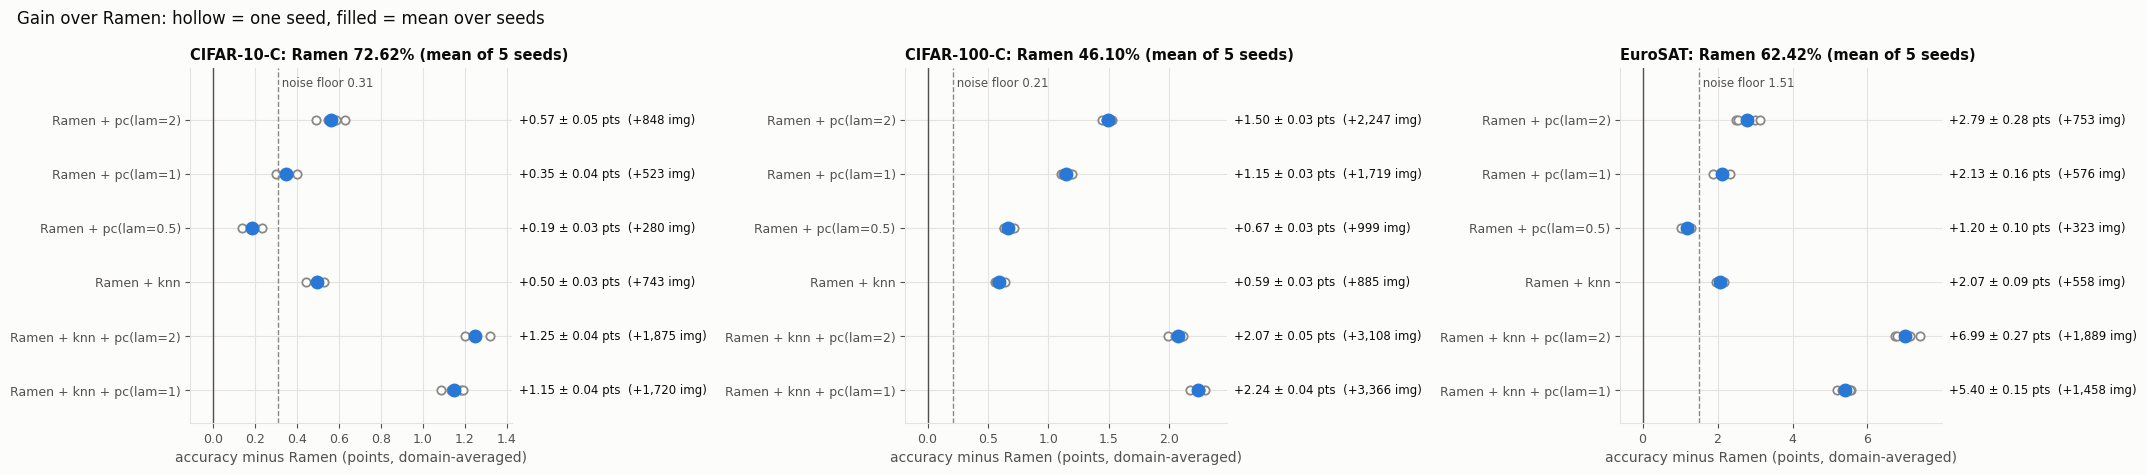

In [6]:
tables = {ds: t[t.dataset == ds].drop(columns='dataset').assign(posthoc=False) for ds in lc.DATASETS}
fig = stack.plot_seed_gains(tables, variants=lc.SHOW)

## 5. Decision (pre-registered rule)

In [7]:
lc.decision(t)

,lam=2 gain,lam=1 gain,noise floor,lam=1 / lam=2,(i) above floor,(ii) >= 50% of lam=2,passes
CIFAR-10-C,0.5652,0.348667,0.31,0.616891,True,True,True
CIFAR-100-C,1.497867,1.145867,0.21,0.764999,True,True,True
EuroSAT,2.79037,2.131852,1.51,0.764003,True,True,True


## 6. Interpretation

**λ = 1 passes the pre-registered rule on all three datasets.** It becomes the single prior-correction setting for every dataset and goes to the held-out test unchanged.

| | λ = 2 (tuned here) | λ = 1 (frozen) | kept | floor |
|---|---|---|---|---|
| CIFAR-10-C | +0.57 ± 0.05 | +0.35 ± 0.04 (4/5 seeds above floor) | 62% | 0.31 |
| CIFAR-100-C | +1.50 ± 0.03 | +1.15 ± 0.03 (5/5) | 76% | 0.21 |
| EuroSAT | +2.79 ± 0.28 | +2.13 ± 0.16 (5/5) | 76% | 1.51 |

- **λ = 1 costs something on the small datasets, but much less than λ = 2 costs on the large ones.** It gives up 0.2–0.7 pts here, while λ = 2 instead of 1 loses 0.4 on ImageNet-C (T3 + pc +0.72 vs +1.13) and 0.6 on DomainNet (−0.19 vs +0.41). One setting across five datasets is worth that trade.
- **CIFAR-10-C is the thin margin.** +0.35 clears the 0.31 floor on the mean, but seed min +0.30 does not. It passes the rule as written, but just barely.
- **With kNN, λ = 1 holds up on CIFAR:** knn + pc(λ=1) +1.15 (C10) and +2.24 (C100, higher than λ = 2's +2.07). EuroSAT drops from +6.99 to +5.40. kNN is still not part of the frozen setting, because it hurts on ImageNet-C.
- **λ = 0.5 is too weak on the small datasets:** it falls below the floor on CIFAR-10-C (+0.19) and EuroSAT (+1.20). So the useful range of a single λ is about 1, not "the smaller the better".

**Caveats.** λ = 1 was chosen on ImageNet-C / DomainNet results, and this check only shows it does not break the datasets λ = 2 was tuned on. It is not a held-out confirmation: all five datasets have now been looked at. The 0.03 EuroSAT sanity gap is unexplained (section 3) and does not affect the comparison.

**Next step.** The held-out test (#3): T3 + pc(λ = 1), no kNN, on a dataset none of this was tuned on (ImageNet-R / -A / -Sketch). Step #2, estimating the class prior instead of assuming it uniform, tunes on ImageNet-C / DomainNet again. Run it after the held-out data and settings are frozen, or keep its winner out of the held-out claim.


## 7. Glossary

| Term | Meaning |
|---|---|
| Ramen | CLIP zero-shot + per-class memory of (feature, entropy gradient); one signSGD step per batch from retrieved entries, predict, reset |
| pc (prior correction) | subtract λ·log(estimated predicted-class share / uniform) from the logits, pushing over-predicted classes down |
| λ | strength of the prior correction; λ = 0 is plain Ramen |
| knn (kNN smoothing) | mix a prediction 50/50 with the predictions on the 10 most similar earlier images |
| T3 | zero-shot-weighted active set at temperature 3 (RamenActive); helps only with large label spaces |
| noise floor | 2 × (max − min) of Ramen's accuracy over seeds 0–4; a gain must exceed it to count |
| pre-registered | the setting and the decision rule were written down before the numbers were computed |
| domain-averaged accuracy | mean of per-domain accuracies (EuroSAT has a single domain) |